# Python fundamentals for the statistics labs

Use this notebook as preparation or a reference while working through Labs 1–4. Start with the
section you need: running cells; variables and collections; conditions and loops; functions;
arrays; reading tables; filtering and summarising; joins; or practice tasks.

Run a cell with **Shift+Enter**. Names refer to values created by earlier cells: run from the top
when starting a session. Use **Restart Kernel and Run All Cells** to check that your analysis
does not depend on unrecorded steps. The examples and practice answers are in this one notebook.

In [1]:
from pathlib import Path
import csv
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA = Path('data') if Path('data/DM_1.csv').exists() else Path('python-fundamentals/data')
if not (DATA / 'DM_1.csv').exists():
    raise FileNotFoundError('Open this notebook from python-fundamentals or the repository root.')

## 1. Variables, numbers and strings

Python is dynamically typed: a name can be reassigned to a value of a different type. Values
still have types, and operations must make sense for those types. Use `type()` to inspect one.
`int` represents integers, `float` represents floating-point numbers, `bool` represents true/false,
and `str` represents text. A numeric identifier is still an identifier in a statistical analysis.

In [2]:
participants = 27
mean_time = 73.89
is_complete = True
course = 'Statistics for Analytics'
for value in [participants, mean_time, is_complete, course, 8+2j]:
    print(value, type(value))
print('Square:', participants**2, 'Absolute value:', abs(-10.1), 'Rounded:', round(mean_time, 1))
print('Division:', 5/2, 'Integer division:', 5//2, 'Remainder:', 5%2)
name = '  university of edinburgh  '
print(name.strip().title())
print(course.lower(), course.upper(), course.replace('Analytics', 'Business'))
print(f'{participants} participants have a mean time of {mean_time:.2f} seconds.')

27 <class 'int'>
73.89 <class 'float'>
True <class 'bool'>
Statistics for Analytics <class 'str'>
(8+2j) <class 'complex'>
Square: 729 Absolute value: 10.1 Rounded: 73.9
Division: 2.5 Integer division: 2 Remainder: 1
University Of Edinburgh
statistics for analytics STATISTICS FOR ANALYTICS Statistics for Business
27 participants have a mean time of 73.89 seconds.


## 2. Lists, tuples, sets and dictionaries

A list is an ordered, mutable collection. Indexing starts at 0; a slice excludes its upper bound.
A tuple is an ordered collection whose entries cannot be reassigned. A set stores distinct items
without a positional order. A dictionary maps unique keys to values.

In [3]:
names = ['Johannes', 'Giovanni', 'Rose', 'Yongzhe', 'Luciana', 'Imani']
print('Second:', names[1], 'Last:', names[-1], 'First three:', names[:3])
names.append('Kumiko')
names.insert(2, 'Roberta')
print('Rose is at index', names.index('Rose'))
print('Sorted view:', sorted(names))
print('Length:', len(names), 'Contains Imani:', 'Imani' in names)
product = ('Notebook', 4.50)
print('Tuple:', product[0], product[1])
capital_city = {'Scotland': 'Edinburgh', 'Wales': 'Cardiff', 'England': 'London'}
print(capital_city['Scotland'])
unique_names = set(['Rose', 'Rose', 'Imani'])
print('Distinct names:', sorted(unique_names))
print('Intersection:', unique_names & {'Rose', 'Galina'})

Second: Giovanni Last: Imani First three: ['Johannes', 'Giovanni', 'Rose']
Rose is at index 3
Sorted view: ['Giovanni', 'Imani', 'Johannes', 'Kumiko', 'Luciana', 'Roberta', 'Rose', 'Yongzhe']
Length: 8 Contains Imani: True
Tuple: Notebook 4.5
Edinburgh
Distinct names: ['Imani', 'Rose']
Intersection: {'Rose'}


Assignment creates another reference to the same list. `.copy()` creates a **shallow copy**:
the outer list is separate, while any nested objects would still be shared.
Strings are immutable; their methods return new strings.

In [4]:
names = ['Rose', 'Imani']
alias = names
alias.append('Kumiko')
copied = names.copy()
copied.remove('Rose')
print('Original and alias:', names, alias)
print('Separate outer list:', copied)
print('Letters:', 'Edinburgh'[3:6])

Original and alias: ['Rose', 'Imani', 'Kumiko'] ['Rose', 'Imani', 'Kumiko']
Separate outer list: ['Imani', 'Kumiko']
Letters: nbu


## 3. Conditions, loops and comprehensions

Indentation defines the body of an `if`, `for` or `while` block. Use `and`, `or` and `not` to
combine single truth values. A `for` loop repeats across a collection; a `while` loop continues
while its condition is true, so its body must make progress towards stopping.

In [5]:
price = 5
if price < 0:
    print('Check the negative price.')
elif price < 1:
    print('Price is below one.')
else:
    print('Price is at least one.')

for index, name in enumerate(names):
    print(index, name)
print('A range excludes its upper bound:', list(range(1, 4)))
countdown = 3
while countdown > 0:
    print(countdown)
    countdown -= 1
evens = [i for i in range(1, 11) if i % 2 == 0]
pairs = [(x, y) for x in [1, 2, 3] for y in [1, 2] if x > y]
print(evens, pairs)

Price is at least one.
0 Rose
1 Imani
2 Kumiko
A range excludes its upper bound: [1, 2, 3]
3
2
1
[2, 4, 6, 8, 10] [(2, 1), (3, 1), (3, 2)]


## 4. Functions and libraries

A function gives a reusable calculation a name. Arguments make its inputs explicit; `return`
provides a value that another calculation can use. `print()` displays text. Prefer a consistent
return type when a function will be used in numerical analysis.
Import a library once and use its chosen alias throughout.

In [6]:
def compound_amount(initial_amount, annual_rate, years):
    return initial_amount * (1 + annual_rate)**years

result = compound_amount(1000, 0.02, 5)
print(f'Amount after five years: {result:.2f}')

import math as m
from math import pi
print(np.add(1, 2), pi, m.sin(1))

Amount after five years: 1104.08
3 3.141592653589793 0.8414709848078965


## 5. NumPy arrays

An array allows a numerical operation across many values. The axis tells a reduction which
dimension to collapse: `axis=0` adds down rows, producing column totals; `axis=1` adds across
columns, producing row totals. A list repeated with `*` and an array multiplied by `*` behave differently.

In [7]:
values = np.array([3, 8, 5])
print('Doubled array:', 2*values, 'Repeated list:', 2*[3, 8, 5])
matrix = np.array([[1, 2, 3], [4, 5, 6]])
print('Shape:', matrix.shape, 'Transpose:', matrix.T)
print('Second row, third column:', matrix[1, 2])
print('Column totals:', matrix.sum(axis=0), 'Row totals:', matrix.sum(axis=1))
print('Zeros:', np.zeros(5))
print('Sample SD:', values.std(ddof=1), 'SD of the listed population:', values.std(ddof=0))

Doubled array: [ 6 16 10] Repeated list: [3, 8, 5, 3, 8, 5]
Shape: (2, 3) Transpose: [[1 4]
 [2 5]
 [3 6]]
Second row, third column: 6
Column totals: [5 7 9] Row totals: [ 6 15]
Zeros: [0. 0. 0. 0. 0.]
Sample SD: 2.516611478423583 SD of the listed population: 2.0548046676563256


## 6. Read files and create tables

`DM_1.csv` is an example table of names, cities and salaries; `DM_2.csv` is a matching exercise
with first name, last name and days active. Its first row is data, so pass `header=None`.
Use a CSV parser to handle commas and quoting. A `with` block closes a file after reading.

In [8]:
with (DATA / 'DM_1.csv').open(encoding='latin1', newline='') as handle:
    records = list(csv.DictReader(handle))
print('First row, selected fields:', {key: records[0][key] for key in ['Name', 'City', 'Salary']})

people = pd.read_csv(DATA / 'DM_1.csv', encoding='latin1')
activity = pd.read_csv(DATA / 'DM_2.csv', header=None,
                       names=['First name', 'Last name', 'Days active'], encoding='latin1')
display(people[['Name', 'City', 'Salary']].head())
display(activity.head())
small_table = pd.DataFrame({'name': ['Rose', 'Imani', 'Rose'], 'years': [2, 5, 3]})
display(small_table)

First row, selected fields: {'Name': 'Brent Hopkins', 'City': 'Mount Pearl', 'Salary': '38363'}


,Name,City,Salary
0,Brent Hopkins,Mount Pearl,38363
1,Colt Bender,Castle Douglas,21506
2,Arthur Hammond,Biloxi,27511
3,Sean Warner,Moere,25201
4,Tate Greene,Ipswich,35052


,First name,Last name,Days active
0,Colt,BENDER,252
1,Arthur,HAMMOND,138
2,Gavin,GIBSON,146
3,Kelly,GARZA,212
4,Zane,PRESTON,234


,name,years
0,Rose,2
1,Imani,5
2,Rose,3


An Excel workbook can contain several tables. Inspect its sheet names, then select the required
sheet explicitly. `read_csv` and `read_excel` both return a pandas DataFrame.

In [9]:
with pd.ExcelFile(DATA / 'dataframe-examples.xlsx') as workbook:
    print('Sheets:', workbook.sheet_names)
    spatial = pd.read_excel(workbook, sheet_name='Spatial')
    people_excel = pd.read_excel(workbook, sheet_name='People')
display(spatial.head())
print('Same people table in CSV and Excel:', people_excel.equals(people))

Sheets: ['People', 'Spatial']


,Age group,Subject,No. correct,% correct,City block score,Study time
0,Elderly,1,9,50.0,17,75
1,Elderly,2,8,44.4,15,90
2,Elderly,3,9,50.0,21,40
3,Elderly,4,6,33.3,34,40
4,Elderly,5,5,27.8,35,25


Same people table in CSV and Excel: True


## 7. Select, filter, summarise and plot

`table['column']` selects a Series; a list of column names selects a smaller DataFrame.
`.loc` selects by label or condition; `.iloc` selects by position. A label slice includes its
ending label, whereas a positional slice excludes its ending position.

For a Series of conditions use `&` and `|` with parentheses. Check missing values and row counts
before summarising. An identifier's numeric storage does not make its average meaningful.

In [10]:
display(spatial[['Age group', 'Study time']].head())
display(spatial.loc[spatial['Age group'].eq('Young'), ['Study time', 'City block score']].head())
display(spatial.iloc[0:3])
print('Missing values per column:')
print(spatial.isna().sum())
print('Group sizes:')
print(spatial['Age group'].value_counts())

selected_columns = ['Study time', 'No. correct', 'City block score']
display(spatial[selected_columns].describe())
display(spatial.groupby('Age group')[selected_columns].agg(['mean', 'median', 'std']).round(2))
# A new column is a calculation for each participant.
spatial['exact proportion'] = spatial['No. correct'] / 18
display(spatial[['No. correct', 'exact proportion']].head())

,Age group,Study time
0,Elderly,75
1,Elderly,90
2,Elderly,40
3,Elderly,40
4,Elderly,25


,Study time,City block score
14,90,14
15,90,29
16,100,16
17,55,22
18,145,11


,Age group,Subject,No. correct,% correct,City block score,Study time
0,Elderly,1,9,50.0,17,75
1,Elderly,2,8,44.4,15,90
2,Elderly,3,9,50.0,21,40


Missing values per column:
Age group           0
Subject             0
No. correct         0
% correct           0
City block score    0
Study time          0
dtype: int64
Group sizes:
Age group
Elderly    14
Young      13
Name: count, dtype: int64


,Study time,No. correct,City block score
count,27.000000,27.000000,27.000000
mean,73.888889,9.259259,21.333333
std,35.500090,2.942952,11.734237
min,25.000000,5.000000,4.000000
25%,42.500000,7.500000,12.500000
50%,70.000000,8.000000,21.000000
75%,97.500000,11.000000,30.500000
max,145.000000,16.000000,43.000000


Study time               No. correct              City block score  \
                mean median    std        mean median   std             mean   
Age group                                                                      
Elderly        50.71   42.5  22.52        7.50    8.0  1.16            27.71   
Young          98.85   95.0  29.66       11.15   11.0  3.13            14.46   

                        
          median   std  
Age group               
Elderly     27.5  9.67  
Young       12.0  9.92

,No. correct,exact proportion
0,9,0.500000
1,8,0.444444
2,9,0.500000
3,6,0.333333
4,5,0.277778


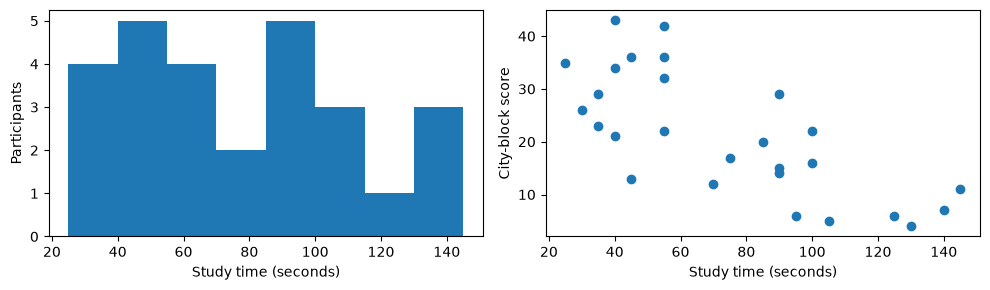

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
spatial['Study time'].plot.hist(bins=8, ax=axes[0])
axes[0].set(xlabel='Study time (seconds)', ylabel='Participants')
axes[1].scatter(spatial['Study time'], spatial['City block score'])
axes[1].set(xlabel='Study time (seconds)', ylabel='City-block score')
plt.tight_layout()
plt.show()

## 8. Prepare keys and join tables

The activity table splits names across two columns. Standardise the case and combine them before
matching. In real research data, prefer a documented unique identifier to a name.

An inner join retains matched rows; a left join retains every left-hand row; a right join retains
every right-hand row; an outer join retains rows from both. Repeated keys can expand the row count
and accidentally give some people greater weight in a later average.

In [12]:
activity['Name'] = activity['First name'].str.strip().str.title() + ' ' + activity['Last name'].str.strip().str.title()
activity_for_join = activity[['Name', 'Days active']]
print('People names unique:', people['Name'].is_unique)
print('Activity names unique:', activity_for_join['Name'].is_unique)
display(activity_for_join.loc[activity_for_join['Name'].duplicated(keep=False)])

join_rows = []
for how in ['left', 'right', 'inner', 'outer']:
    joined = people.merge(activity_for_join, on='Name', how=how, validate='one_to_many', indicator=True)
    join_rows.append([how, len(joined), (joined['_merge']=='left_only').sum(), (joined['_merge']=='right_only').sum()])
display(pd.DataFrame(join_rows, columns=['join', 'rows', 'left only', 'right only']))

joined = people.merge(activity_for_join, on='Name', how='left', validate='one_to_many')
display(joined[['Name', 'Salary', 'Days active']].head())
# Writing to an in-memory buffer demonstrates CSV output without creating another data file.
buffer = io.StringIO()
joined[['Name', 'Salary', 'Days active']].head().to_csv(buffer, index=False)
print(buffer.getvalue())

People names unique: True
Activity names unique: False


,Name,Days active
4,Zane Preston,234
5,Zane Preston,178
7,Elvis Collier,95
8,Elvis Collier,101
9,Elvis Collier,258


,join,rows,left only,right only
0,left,23,10,0
1,right,14,0,1
2,inner,13,0,0
3,outer,24,10,1


,Name,Salary,Days active
0,Brent Hopkins,38363,NaN
1,Colt Bender,21506,252.0
2,Arthur Hammond,27511,138.0
3,Sean Warner,25201,NaN
4,Tate Greene,35052,NaN


Name,Salary,Days active
Brent Hopkins,38363,
Colt Bender,21506,252.0
Arthur Hammond,27511,138.0
Sean Warner,25201,
Tate Greene,35052,



**Check:** Explain why the left join can have more rows than the people table. Decide whether an
analysis needs one person, one activity record or a person-level activity summary per row.
Choose that unit before aggregating duplicates.

## 9. Practice with worked checks

Try each task before opening its worked check. The code below the check is runnable as a reference.

### Practice 1 — Compound interest
Starting with 1,000 at 10% annual interest, calculate the amount after five years.

<details>
<summary>Check your reasoning</summary>

Multiply by 1.1 five times, or calculate `1000 * 1.1**5`. The result is 1,610.51.

</details>

In [13]:
amount = 1000
for year in range(5):
    amount *= 1.10
print(round(amount, 2))

1610.51


### Practice 2 — Years to a target
How many complete years does it take for 1,000 at 2% annual interest to reach at least 2,000?

<details>
<summary>Check your reasoning</summary>

Update the amount and year count until the target is reached. The first complete year meeting the target is 36.

</details>

In [14]:
amount, target, annual_rate, years = 1000, 2000, 0.02, 0
while amount < target:
    amount *= 1 + annual_rate
    years += 1
print(years, round(amount, 2))

36 2039.89


### Practice 3 — Distinct names
Remove repeated names while preserving their first-occurrence order.

<details>
<summary>Check your reasoning</summary>

A dictionary preserves insertion order; `list(dict.fromkeys(names))` gives distinct names in that order. A set gives distinct names without that ordering guarantee.

</details>

In [15]:
name_list = ['Johannes', 'Jamal', 'Jamal', 'Johannes', 'Galina']
print(list(dict.fromkeys(name_list)))

['Johannes', 'Jamal', 'Galina']


### Practice 4 — Selected letters
Collect the fourth and sixth letters of each word with at least six letters.

<details>
<summary>Check your reasoning</summary>

Use indexes 3 and 5, and filter with `len(word) >= 6`. The same rule must apply to every word.

</details>

In [16]:
words = ['Johannes', 'Jamal', 'Galina']
print([word[3] + word[5] for word in words if len(word) >= 6])

['an', 'ia']


### Practice 5 — Temperature conversion
Convert [15, 18, 32, 19] degrees Celsius to Fahrenheit using F = 9C/5 + 32.

<details>
<summary>Check your reasoning</summary>

The values are 59.0, 64.4, 89.6 and 66.2 degrees Fahrenheit. A comprehension applies the same transformation to each value.

</details>

In [17]:
celsius = [15, 18, 32, 19]
fahrenheit = [9*value/5 + 32 for value in celsius]
print(fahrenheit)

[59.0, 64.4, 89.6, 66.2]


### Practice 6 — Reuse a function
Calculate years to a target for several starting amounts and positive rates. Make the target an explicit argument.

In [18]:
def years_to_target(amount, annual_rate, target):
    if amount <= 0 or target <= 0 or annual_rate <= 0:
        raise ValueError('Use positive amounts and an annual rate above zero.')
    years = 0
    while amount < target:
        amount *= 1 + annual_rate
        years += 1
    return years

for amount in [1000, 1200, 1300]:
    for rate in [0.02, 0.05, 0.10]:
        print(amount, rate, years_to_target(amount, rate, 2000))

1000 0.02 36
1000 0.05 15
1000 0.1 8
1200 0.02 26
1200 0.05 11
1200 0.1 6
1300 0.02 22
1300 0.05 9
1300 0.1 5


### Practice 7 — Dictionary lookup
Use course names to find the credits taught by each person.

In [19]:
courses = {'Johannes': 'Web Analytics', 'Jamal': 'DEA', 'Maurizio': 'Simulation'}
credits = {'Web Analytics': 15, 'DEA': 15, 'Simulation': 15}
for person, course in courses.items():
    print(f'{person} teaches {credits[course]} credits.')

Johannes teaches 15 credits.
Jamal teaches 15 credits.
Maurizio teaches 15 credits.


### Practice 8 — Most frequent third letter
Count third letters, allowing for short words, and report all tied modes.

In [20]:
from collections import Counter
words = ['Johannes', 'Jamal', 'Jamal', 'Adme', 'Galina', 'Al']
letter_counts = Counter(word[2] for word in words if len(word) >= 3)
largest_count = max(letter_counts.values(), default=0)
modes = [letter for letter, count in letter_counts.items() if count == largest_count]
print(dict(letter_counts), 'Most frequent:', modes)

{'h': 1, 'm': 3, 'l': 1} Most frequent: ['m']


## Data guide

`data/DM_1.csv` and `data/DM_2.csv` are course examples for file reading and joining. Treat their
names and other fields as records for practising table operations. Population inference
requires a defined population and sampling design.
`data/dataframe-examples.xlsx` contains the same people table and the 27-participant spatial-memory
table used in Lab 1. Read the relevant sheet explicitly. All four statistical labs use local CSV files.